# CSA47 – Deep Learning | Assignment 1 (CO1) – Python Implementation
**Scenario:** Healthcare Risk Prediction  |  **Total Marks:** 50
**Name:** SOORIYAVEL B **Reg. No.:** 192324090

This notebook implements the numerical parts of every task (Tasks 1–12) with code, so each result in the solution document can be reproduced and verified.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.linear_model import LogisticRegression, SGDClassifier, LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, recall_score,
                             precision_score, f1_score, roc_auc_score, silhouette_score)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

## Task 1 – Patient Data Representation and Normalization (5 Marks)
**a)** Raw features on different scales let large-valued features dominate distances and slow gradient descent.
**b)** Build the feature matrix and apply min-max scaling and z-score standardization.

In [2]:
features = ["Age", "BP", "Glucose", "Cholesterol"]
patients = ["P1", "P2", "P3"]
X = np.array([[45, 130, 110, 200],
              [60, 150, 160, 240],
              [30, 110,  90, 180]], dtype=float)
print("Feature matrix X (3 x 4):")
display(pd.DataFrame(X, index=patients, columns=features))

Feature matrix X (3 x 4):


,Age,BP,Glucose,Cholesterol
P1,45.0,130.0,110.0,200.0
P2,60.0,150.0,160.0,240.0
P3,30.0,110.0,90.0,180.0


In [3]:
# a) Effect of raw features: contribution of each feature to the raw P1-P2 squared distance
diff = X[0] - X[1]
d2 = diff**2
print("Raw Euclidean distance P1-P2:", round(np.sqrt(d2.sum()), 3))
display(pd.DataFrame({"squared diff": d2, "share (%)": 100*d2/d2.sum()}, index=features))

Raw Euclidean distance P1-P2: 68.739


,squared diff,share (%)
Age,225.0,4.7619
BP,400.0,8.4656
Glucose,2500.0,52.9101
Cholesterol,1600.0,33.8624


In [4]:
# b) Min-max scaling: (x - min) / (max - min)
mins, maxs = X.min(axis=0), X.max(axis=0)
X_minmax = (X - mins) / (maxs - mins)
print("Min-max normalized:")
display(pd.DataFrame(X_minmax, index=patients, columns=features))

# Z-score standardization: (x - mean) / std  (population std, ddof=0)
mu, sigma = X.mean(axis=0), X.std(axis=0)
X_z = (X - mu) / sigma
print("Means:", mu, "\nStd  :", sigma)
print("Z-score standardized:")
display(pd.DataFrame(X_z, index=patients, columns=features))

# Numerical verification
print("Z column means (should be 0):", X_z.mean(axis=0).round(10))
print("Z column variances (should be 1):", X_z.var(axis=0).round(10))
print("Min-max range (should be 0..1):", X_minmax.min(axis=0), X_minmax.max(axis=0))

Min-max normalized:


,Age,BP,Glucose,Cholesterol
P1,0.5,0.5,0.2857,0.3333
P2,1.0,1.0,1.0000,1.0000
P3,0.0,0.0,0.0000,0.0000


Means: [ 45.     130.     120.     206.6667] 
Std  : [12.2474 16.3299 29.4392 24.9444]
Z-score standardized:


,Age,BP,Glucose,Cholesterol
P1,0.0000,0.0000,-0.3397,-0.2673
P2,1.2247,1.2247,1.3587,1.3363
P3,-1.2247,-1.2247,-1.0190,-1.0690


Z column means (should be 0): [ 0.  0. -0.  0.]
Z column variances (should be 1): [1. 1. 1. 1.]
Min-max range (should be 0..1): [0. 0. 0. 0.] [1. 1. 1. 1.]


In [5]:
# Distance contribution after normalization
dm = (X_minmax[0] - X_minmax[1])**2
print("Min-max P1-P2 distance:", round(np.sqrt(dm.sum()), 3))
display(pd.DataFrame({"raw share (%)": 100*d2/d2.sum(), "min-max share (%)": 100*dm/dm.sum()}, index=features))

Min-max P1-P2 distance: 1.206


,raw share (%),min-max share (%)
Age,4.7619,17.1863
BP,8.4656,17.1863
Glucose,52.9101,35.0740
Cholesterol,33.8624,30.5534


**c) Why normalization matters.**
*Distance-based methods* (k-NN, K-means): Euclidean distance adds squared differences in raw units, so large-scale features dominate.
*Gradient-based methods*: unequal scales make the loss surface a narrow valley (high condition number) so gradient descent zig-zags and needs a tiny learning rate. The demo below compares convergence.

Condition number raw : 11925553.9
Condition number std : 1.4


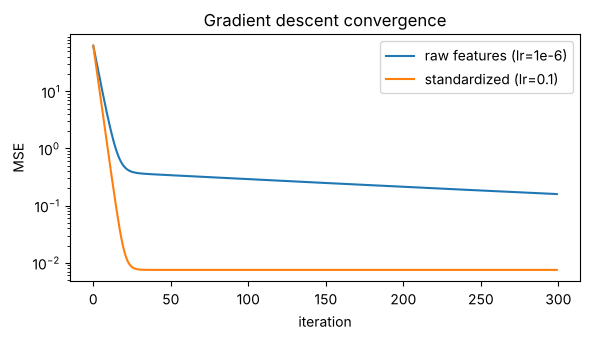

In [6]:
# c) Gradient descent on a least-squares problem: raw vs standardized features
rng = np.random.default_rng(0)
n = 200
raw = np.column_stack([rng.normal(50, 10, n), rng.normal(130, 15, n),
                       rng.normal(120, 30, n), rng.normal(200, 25, n)])
y = (0.02*raw[:,0] + 0.01*raw[:,1] + 0.03*raw[:,2] + 0.01*raw[:,3]) + rng.normal(0, .1, n)

def gd(F, y, lr, iters=300):
    F1 = np.column_stack([np.ones(len(F)), F]); w = np.zeros(F1.shape[1]); losses = []
    for _ in range(iters):
        err = F1 @ w - y
        losses.append((err**2).mean())
        w -= lr * 2 * F1.T @ err / len(y)
        if not np.isfinite(losses[-1]) or losses[-1] > 1e12: break
    return losses

Z = (raw - raw.mean(0)) / raw.std(0)
loss_raw = gd(raw, y, lr=1e-6)     # a larger lr would diverge on raw data
loss_std = gd(Z, y, lr=0.1)
print("Condition number raw :", round(np.linalg.cond(np.column_stack([np.ones(n), raw]).T @ np.column_stack([np.ones(n), raw])), 1))
print("Condition number std :", round(np.linalg.cond(np.column_stack([np.ones(n), Z]).T @ np.column_stack([np.ones(n), Z])), 1))
plt.figure(figsize=(6,3.5))
plt.plot(loss_raw, label="raw features (lr=1e-6)"); plt.plot(loss_std, label="standardized (lr=0.1)")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("MSE"); plt.legend(); plt.title("Gradient descent convergence")
plt.tight_layout(); plt.show()

## Task 2 – Vector Representation and Matrix Operations (2 Marks)
Risk score `s = wᵀx`; for many patients `s = Xw`. Order: (age, glucose, BP, cholesterol).

In [7]:
x = np.array([0.60, 0.80, 0.70, 0.50])     # normalized patient
w = np.array([0.20, 0.35, 0.25, 0.20])     # importance weights (sum = 1)
s = w @ x
print("Weights sum:", w.sum())
print("Contributions:", w * x)
print("Risk score s = w.x =", round(s, 3))

# Matrix form for the Task 1 patients (reorder columns to age, glucose, BP, chol)
Xn = X_minmax[:, [0, 2, 1, 3]]
print("\nScores for P1, P2, P3 (Xw):", Xn @ w)

Weights sum: 1.0
Contributions: [0.12  0.28  0.175 0.1  ]
Risk score s = w.x = 0.675

Scores for P1, P2, P3 (Xw): [0.3917 1.     0.    ]


## Task 3 – Probability and Conditional Probability (6 Marks)
D = disease, E = elevated glucose.

In [8]:
N, n_D, n_DE, n_notD_E = 1000, 200, 160, 120
n_notD = N - n_D
P_D = n_D / N
P_E = (n_DE + n_notD_E) / N                 # a)
P_D_given_E = n_DE / (n_DE + n_notD_E)      # b)
P_E_given_D = n_DE / n_D                    # c)
print(f"a) P(E)   = {P_E:.4f}")
print(f"b) P(D|E) = {P_D_given_E:.4f}")
print(f"c) P(E|D) = {P_E_given_D:.4f}")

# Verification with total probability and Bayes
P_E_notD = n_notD_E / n_notD
print("Total probability check :", P_E_given_D*P_D + P_E_notD*(1-P_D))
print("Bayes check P(D|E)      :", P_E_given_D*P_D / P_E)
print("P(D|not E)              :", round((n_D - n_DE) / (N - 280), 4))
display(pd.DataFrame([[160, 40], [120, 680]], index=["Disease", "No disease"],
                     columns=["Elevated glucose", "Normal glucose"]))

a) P(E)   = 0.2800
b) P(D|E) = 0.5714
c) P(E|D) = 0.8000
Total probability check : 0.28
Bayes check P(D|E)      : 0.5714285714285715
P(D|not E)              : 0.0556


,Elevated glucose,Normal glucose
Disease,160,40
No disease,120,680


**d)** Prior risk is 20 %, but with elevated glucose it rises to ≈57 %, so patients can be ranked by posterior probability for follow-up testing.

## Task 4 – Bayesian Statistics for Disease Classification (4 Marks)

P(+)           = 0.135
P(D | +)       = 0.6667
P(D | -)       = 0.0116
Likelihood ratio = 18.0


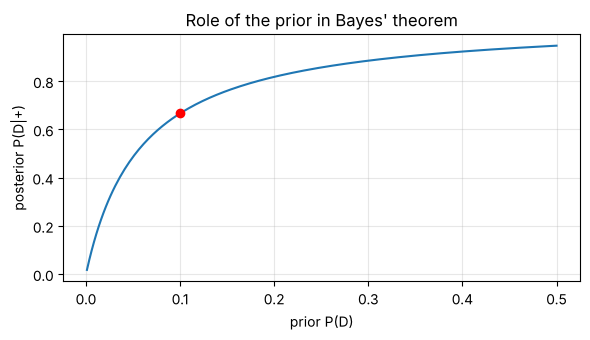

In [9]:
prior, sens, fpr = 0.10, 0.90, 0.05
p_pos = sens*prior + fpr*(1-prior)
posterior = sens*prior / p_pos
print("P(+)           =", round(p_pos, 4))
print("P(D | +)       =", round(posterior, 4))
print("P(D | -)       =", round(((1-sens)*prior) / (1-p_pos), 4))
print("Likelihood ratio =", sens/fpr)

# Effect of prior on posterior
priors = np.linspace(0.001, 0.5, 200)
post = sens*priors / (sens*priors + fpr*(1-priors))
plt.figure(figsize=(6,3.5)); plt.plot(priors, post); plt.scatter([prior],[posterior], c="r", zorder=3)
plt.xlabel("prior P(D)"); plt.ylabel("posterior P(D|+)"); plt.title("Role of the prior in Bayes' theorem")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

**b)** Posterior ∝ likelihood × prior: the prior is the base rate, the likelihood shows how strongly the test result supports disease. **c)** Bayesian updating combines background knowledge with uncertain evidence and gives probabilities, not hard labels.

## Task 5 – Entropy and Information Gain (3 Marks)

a) Entropy of risk classification H = 0.971 bits (max 1 bit for two classes)
H(high glucose) = 0.8813 | H(normal glucose) = 0.469
Weighted entropy after split = 0.6751
Information gain IG(glucose) = 0.2958 bits


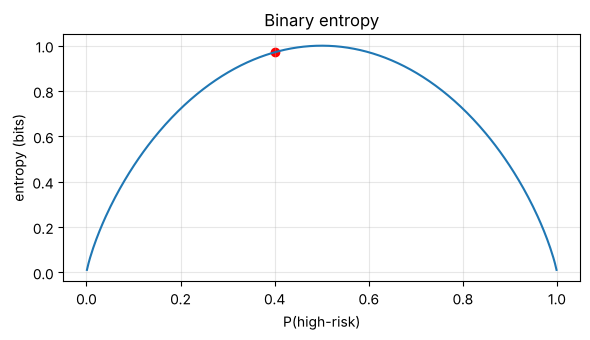

In [10]:
def entropy(counts):
    p = np.array(counts, dtype=float); p = p / p.sum(); p = p[p > 0]
    return -(p * np.log2(p)).sum()

H = entropy([40, 60])
print("a) Entropy of risk classification H =", round(H, 4), "bits (max 1 bit for two classes)")

# c) Information gain for an assumed glucose split
high_g, low_g = [35, 15], [5, 45]      # [high-risk, low-risk] counts
H_after = (sum(high_g)/100)*entropy(high_g) + (sum(low_g)/100)*entropy(low_g)
print("H(high glucose) =", round(entropy(high_g), 4), "| H(normal glucose) =", round(entropy(low_g), 4))
print("Weighted entropy after split =", round(H_after, 4))
print("Information gain IG(glucose) =", round(H - H_after, 4), "bits")

p = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(6,3.5)); plt.plot(p, -(p*np.log2(p)+(1-p)*np.log2(1-p)))
plt.scatter([0.4],[H], c="r"); plt.xlabel("P(high-risk)"); plt.ylabel("entropy (bits)")
plt.title("Binary entropy"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## Task 6 – Numerical Computation and Distance Measurement (3 Marks)

In [11]:
A = np.array([0.70, 0.80, 0.60]); B = np.array([0.50, 0.75, 0.90])   # glucose, BP, cholesterol
sq = (A - B)**2
print("Squared differences (glucose, BP, chol):", sq, "sum =", sq.sum())
d = np.sqrt(sq.sum())
print("a) Euclidean distance d(A,B) =", round(d, 4))
print("   np.linalg.norm check      =", round(np.linalg.norm(A - B), 4))
print("   Max possible distance sqrt(3) =", round(np.sqrt(3), 4), "-> relative distance", round(d/np.sqrt(3), 3))
print("   Contribution of cholesterol to d^2 (%):", round(100*sq[2]/sq.sum(), 1))

Squared differences (glucose, BP, chol): [0.04   0.0025 0.09  ] sum = 0.1325
a) Euclidean distance d(A,B) = 0.364
   np.linalg.norm check      = 0.364
   Max possible distance sqrt(3) = 1.7321 -> relative distance 0.21
   Contribution of cholesterol to d^2 (%): 67.9


**b)** A smaller distance means more similar patients. **c)** Without normalization, features with large numeric ranges dominate the distance (Task 1: glucose gave 53 % of the raw distance).

## Task 7 – Bias–Variance Trade-off (4 Marks)
Polynomial regression of different degrees on noisy data: degree 1 → high bias, degree 15 → high variance, degree 3–4 → good fit.

In [12]:
rng = np.random.default_rng(42)
def true_f(x): return np.sin(2*np.pi*x)
x_tr = rng.uniform(0, 1, 30); y_tr = true_f(x_tr) + rng.normal(0, .25, 30)
x_va = rng.uniform(0, 1, 200); y_va = true_f(x_va) + rng.normal(0, .25, 200)

rows = {}
for name, deg in [("Model A (degree 1)", 1), ("Model C (degree 4)", 4), ("Model B (degree 15)", 15)]:
    m = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    m.fit(x_tr[:, None], y_tr)
    tr = np.mean((m.predict(x_tr[:, None]) - y_tr)**2); va = np.mean((m.predict(x_va[:, None]) - y_va)**2)
    rows[name] = (tr, va)
df = pd.DataFrame(rows, index=["train MSE", "validation MSE"]).T
df["diagnosis"] = ["High bias (underfit)", "Good balance", "High variance (overfit)"]
display(df)

,train MSE,validation MSE,diagnosis
Model A (degree 1),0.1931,0.1997,High bias (underfit)
Model C (degree 4),0.0444,0.0616,Good balance
Model B (degree 15),0.0309,0.0851,High variance (overfit)


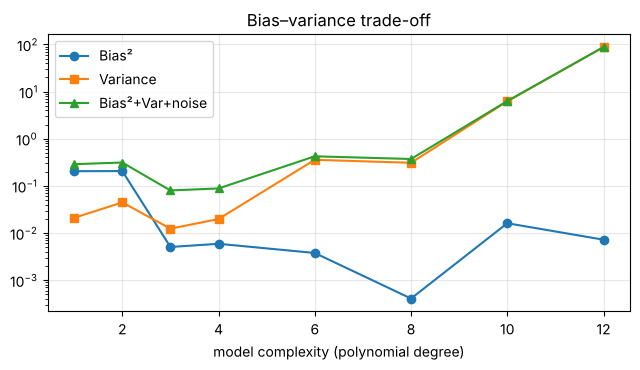

In [13]:
# Estimate bias^2 and variance empirically by refitting on many training sets
xt = np.linspace(0, 1, 100)
def bias_var(deg, reps=200):
    preds = []
    for _ in range(reps):
        xs = rng.uniform(0, 1, 30); ys = true_f(xs) + rng.normal(0, .25, 30)
        m = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression()).fit(xs[:, None], ys)
        preds.append(m.predict(xt[:, None]))
    preds = np.array(preds); mean_pred = preds.mean(0)
    return ((mean_pred - true_f(xt))**2).mean(), preds.var(0).mean()

degs = [1, 2, 3, 4, 6, 8, 10, 12]
res = np.array([bias_var(d) for d in degs])
plt.figure(figsize=(6.5,3.8))
plt.plot(degs, res[:,0], "o-", label="Bias²"); plt.plot(degs, res[:,1], "s-", label="Variance")
plt.plot(degs, res.sum(1) + 0.25**2, "^-", label="Bias²+Var+noise")
plt.yscale("log"); plt.xlabel("model complexity (polynomial degree)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Bias–variance trade-off"); plt.tight_layout(); plt.show()

| Model | Behaviour | Diagnosis | Improvement |
|---|---|---|---|
| A | high train & validation error | **High bias** | more capacity, better features, less regularization |
| B | very low train, high validation error | **High variance** | more data, regularization, early stopping, simpler model |
| C | low & similar errors | good fit | keep |

## Task 8 – Overfitting, Underfitting and Model Capacity (4 Marks)

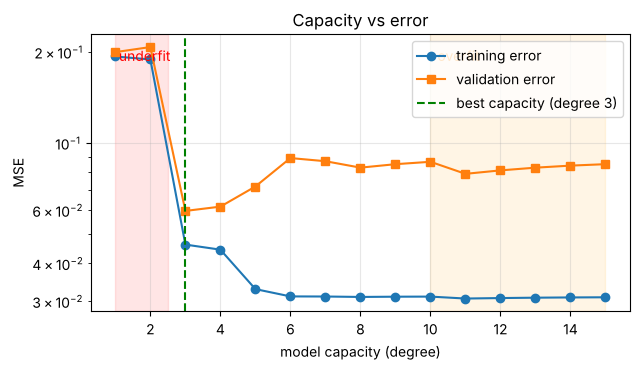

Simple model  -> underfitting | Moderate model -> good generalization | Complex model -> overfitting


In [14]:
caps = range(1, 16)
tr_err, va_err = [], []
for deg in caps:
    m = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression()).fit(x_tr[:, None], y_tr)
    tr_err.append(np.mean((m.predict(x_tr[:, None]) - y_tr)**2))
    va_err.append(np.mean((m.predict(x_va[:, None]) - y_va)**2))
best = int(np.argmin(va_err)) + 1
plt.figure(figsize=(6.5,3.8))
plt.plot(caps, tr_err, "o-", label="training error"); plt.plot(caps, va_err, "s-", label="validation error")
plt.axvline(best, ls="--", c="g", label=f"best capacity (degree {best})")
plt.axvspan(1, 2.5, alpha=.1, color="r"); plt.axvspan(10, 15, alpha=.1, color="orange")
plt.text(1.1, max(va_err[:12])*0.9, "underfit", color="r"); plt.text(10.2, max(va_err[:12])*0.9, "overfit", color="darkorange")
plt.yscale("log"); plt.xlabel("model capacity (degree)"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=.3)
plt.title("Capacity vs error"); plt.tight_layout(); plt.show()
print("Simple model  -> underfitting | Moderate model -> good generalization | Complex model -> overfitting")

Increasing capacity first reduces bias so both errors fall; beyond the optimum the model memorizes noise, training error keeps falling while validation error rises (the generalization gap widens).

## Synthetic patient dataset (used for Tasks 9–12)
Since no real data are provided, a synthetic dataset with the assignment's features is generated: age, BP, glucose, cholesterol, family history, and a disease label that depends on them probabilistically.

In [15]:
def make_patients(n, seed=0, miss_rate=0.0):
    r = np.random.default_rng(seed)
    age  = r.normal(50, 12, n).clip(18, 90)
    bp   = r.normal(125, 15, n) + 0.3*(age-50)
    glu  = r.normal(105, 25, n) + 0.4*(age-50)
    chol = r.normal(200, 30, n) + 0.3*(age-50)
    fam  = r.binomial(1, 0.25, n)
    logit = -9.0 + 0.03*(age-50) + 0.02*bp + 0.035*glu + 0.01*chol + 0.9*fam
    y = r.binomial(1, 1/(1+np.exp(-logit)))
    df = pd.DataFrame({"Age": age, "BP": bp, "Glucose": glu, "Cholesterol": chol, "FamilyHistory": fam, "Disease": y})
    if miss_rate > 0:
        for c in ["BP", "Glucose", "Cholesterol"]:
            df.loc[r.random(n) < miss_rate, c] = np.nan
    return df

data = make_patients(5000, seed=1)
print("Disease prevalence:", data.Disease.mean().round(3))
display(data.head())

Disease prevalence: 0.38


,Age,BP,Glucose,Cholesterol,FamilyHistory,Disease
0,54.1470,135.2363,92.1169,168.2191,0,0
1,59.8594,137.9428,86.7108,186.9459,0,0
2,53.9652,120.9999,118.7780,206.1749,0,0
3,34.3621,127.8751,115.7041,219.4474,0,1
4,60.8643,121.3005,88.4897,262.2452,0,1


## Task 9 – Supervised Learning and Model Evaluation (3 Marks)

In [16]:
Xd, yd = data.drop(columns="Disease"), data["Disease"]
X_train, X_test, y_train, y_test = train_test_split(Xd, yd, test_size=0.2, stratify=yd, random_state=0)
print("Train:", X_train.shape, " Test:", X_test.shape)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
pred = clf.predict(X_test)
print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print("Sensitivity (recall):", round(recall_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4), "| F1:", round(f1_score(y_test, pred), 4))
print("AUC      :", round(roc_auc_score(y_test, clf.predict_proba(X_test)[:,1]), 4))
print("Majority-class baseline accuracy:", round(1 - y_test.mean(), 4))
display(pd.DataFrame(confusion_matrix(y_test, pred), index=["actual 0", "actual 1"], columns=["pred 0", "pred 1"]))

# Task statement: 92 of 100 correct
correct, total = 92, 100
print(f"\nAccuracy (92 of 100) = {correct}/{total} = {correct/total:.0%}")

Train: (4000, 5)  Test: (1000, 5)
Accuracy : 0.714
Sensitivity (recall): 0.5395
Precision: 0.6487 | F1: 0.5891
AUC      : 0.7664
Majority-class baseline accuracy: 0.62


,pred 0,pred 1
actual 0,509,111
actual 1,175,205



Accuracy (92 of 100) = 92/100 = 92%


Accuracy of 92 % means 8 % of unseen patients are misclassified. With class imbalance accuracy alone can mislead, so sensitivity, specificity, precision and AUC should also be reported.

## Task 10 – Unsupervised Learning and Patient Grouping (4 Marks)
K-means on normalized features (no labels used).

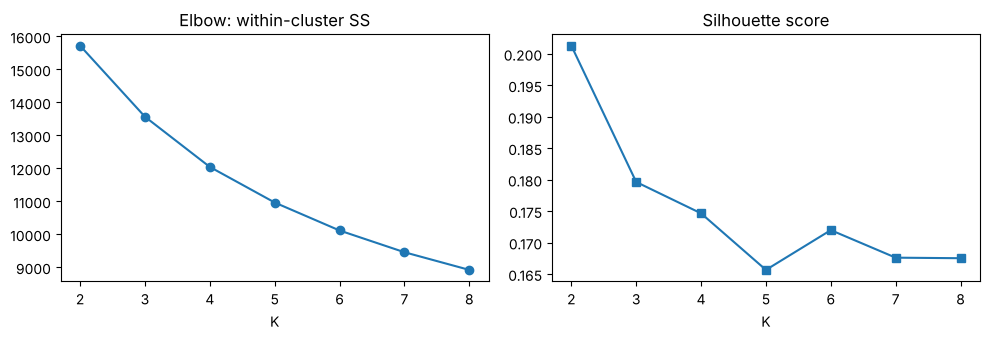

In [17]:
cols = ["Age", "BP", "Glucose", "Cholesterol"]
Z = StandardScaler().fit_transform(data[cols])

# Choose K with elbow (inertia) and silhouette
ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_, sample_size=2000, random_state=0))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow: within-cluster SS"); ax[0].set_xlabel("K")
ax[1].plot(ks, sil, "s-"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("K")
plt.tight_layout(); plt.show()

Cluster profiles (original units):


,Age,BP,Glucose,Cholesterol,FamilyHistory,Size,Disease rate (for validation only)
Cluster,,,,,,,
0,42.1060,116.7493,99.9918,176.7919,0.2477,1756,0.2403
1,59.0923,131.8649,125.6586,201.5930,0.2348,1623,0.6081
2,48.9404,126.5707,88.2068,222.8310,0.2480,1621,0.3041


Distances of patient 0 to centroids: [1.631  1.7902 1.9709] -> cluster 0


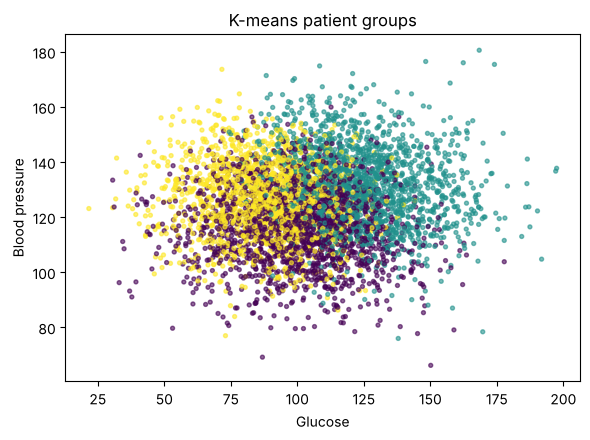

In [18]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
data["Cluster"] = km.labels_
profile = data.groupby("Cluster")[cols + ["FamilyHistory"]].mean()
profile["Size"] = data.groupby("Cluster").size()
profile["Disease rate (for validation only)"] = data.groupby("Cluster")["Disease"].mean()
print("Cluster profiles (original units):")
display(profile)

# Distance of a patient to each centroid -> similarity
pt = Z[0]
print("Distances of patient 0 to centroids:", np.linalg.norm(km.cluster_centers_ - pt, axis=1), "-> cluster", km.labels_[0])

plt.figure(figsize=(6,4.5))
plt.scatter(data.Glucose, data.BP, c=data.Cluster, s=8, cmap="viridis", alpha=.6)
plt.xlabel("Glucose"); plt.ylabel("Blood pressure"); plt.title("K-means patient groups"); plt.tight_layout(); plt.show()

In [19]:
# Manual K-means on the tiny example from the solution document (age, glucose min-max values)
pts = np.array([[0.5, 0.286], [1, 1], [0, 0]]); cents = pts[[1, 2]].copy()
for it in range(5):
    d = np.linalg.norm(pts[:, None] - cents[None], axis=2); lab = d.argmin(1)
    new = np.array([pts[lab == k].mean(0) for k in range(2)])
    print(f"iter {it}: distances={d.round(3).tolist()} labels={lab} centroids={new.round(3).tolist()}")
    if np.allclose(new, cents): break
    cents = new

iter 0: distances=[[0.872, 0.576], [0.0, 1.414], [1.414, 0.0]] labels=[1 0 1] centroids=[[1.0, 1.0], [0.25, 0.143]]
iter 1: distances=[[0.872, 0.288], [0.0, 1.139], [1.414, 0.288]] labels=[1 0 1] centroids=[[1.0, 1.0], [0.25, 0.143]]


Clusters support further clinical investigation (e.g. a group with high BP and glucose may be screened first) but they are decision support only and do not replace medical diagnosis.

## Task 11 – Comparison of Supervised and Unsupervised Learning (4 Marks)

In [20]:
comparison = pd.DataFrame({
    "Supervised (Dataset A)": ["features + labels", "learn f(x) ≈ y", "class / probability", "accuracy, sensitivity, AUC", "logistic regression, trees, neural nets"],
    "Unsupervised (Dataset B)": ["features only", "discover structure / groups", "clusters, centroids", "silhouette, inertia, clinical validity", "K-means, hierarchical, PCA"]},
    index=["Data", "Objective", "Output", "Evaluation", "Examples"])
display(comparison)

# Empirical illustration: cluster IDs alone cannot predict disease as well as a supervised model
from sklearn.metrics import adjusted_rand_score
print("Supervised AUC (Task 9)             :", round(roc_auc_score(y_test, clf.predict_proba(X_test)[:,1]), 4))
print("Adjusted Rand: clusters vs disease  :", round(adjusted_rand_score(data.Disease, data.Cluster), 4), "(≈0 => clusters ≠ labels)")

,Supervised (Dataset A),Unsupervised (Dataset B)
Data,features + labels,features only
Objective,learn f(x) ≈ y,discover structure / groups
Output,class / probability,"clusters, centroids"
Evaluation,"accuracy, sensitivity, AUC","silhouette, inertia, clinical validity"
Examples,"logistic regression, trees, neural nets","K-means, hierarchical, PCA"


Supervised AUC (Task 9)             : 0.7664
Adjusted Rand: clusters vs disease  : 0.0689 (≈0 => clusters ≠ labels)


**Recommendation:** use a supervised classifier (trained on labelled Dataset A with normalized features) to predict disease for a new patient; use clustering on Dataset B for exploration or as extra features.

## Task 12 – Design Challenge: Selecting and Adapting a Learning Strategy (8 Marks)
**Decision: modify** – keep normalization + supervised classifier, add imputation, scalable mini-batch learning and an unsupervised clustering stage.

### A. Impact analysis – scale, memory and complexity

In [21]:
# A) Cost growth from 10,000 to 1,000,000 records
n_small, n_big, d = 10_000, 1_000_000, 5
print("Memory of feature matrix (float64): %.2f MB -> %.2f MB" % (n_small*d*8/1e6, n_big*d*8/1e6))
print("Pairwise distances O(n^2): %.1e -> %.1e (x%d)" % (n_small**2, n_big**2, (n_big/n_small)**2))
print("K-means / SGD O(n)       : x%d" % (n_big/n_small))

# Measure how runtime scales for exact k-NN style pairwise distances vs K-means
from sklearn.metrics import pairwise_distances
for n in [1000, 2000, 4000]:
    Xs = np.random.default_rng(0).normal(size=(n, d))
    t0 = time.time(); pairwise_distances(Xs); t1 = time.time() - t0
    t0 = time.time(); MiniBatchKMeans(5, n_init=1, random_state=0).fit(Xs); t2 = time.time() - t0
    print(f"n={n:5d} | pairwise: {t1:.4f}s | mini-batch K-means: {t2:.4f}s")

Memory of feature matrix (float64): 0.40 MB -> 40.00 MB
Pairwise distances O(n^2): 1.0e+08 -> 1.0e+12 (x10000)
K-means / SGD O(n)       : x100
n= 1000 | pairwise: 0.0100s | mini-batch K-means: 0.0151s
n= 2000 | pairwise: 0.0439s | mini-batch K-means: 0.0117s


n= 4000 | pairwise: 0.1991s | mini-batch K-means: 0.0215s


### Numerical stability at scale – streaming mean/variance (Welford)

In [22]:
def welford(stream):
    n = 0; mean = 0.0; M2 = 0.0
    for v in stream:
        n += 1; delta = v - mean; mean += delta / n; M2 += delta * (v - mean)
    return mean, M2 / n

vals = np.random.default_rng(0).normal(1e6, 5, 200_000)       # large offset -> naive formulas lose precision
naive_var = (vals**2).mean() - vals.mean()**2
print("Welford  mean/var:", welford(vals))
print("Naive    var     :", naive_var, "| np.var:", vals.var())

Welford  mean/var: (np.float64(1000000.0006533784), np.float64(25.060032768631196))
Naive    var     : 25.0601806640625 | np.var: 25.06003276863373


### B/C. Data quality: missing values and different scales

In [23]:
big = make_patients(300_000, seed=7, miss_rate=0.08)        # scaled-down stand-in for 1,000,000 records
print("Missing values per column:\n", big.isna().sum().to_string())
feat_cols = ["Age", "BP", "Glucose", "Cholesterol", "FamilyHistory"]
Xb, yb = big[feat_cols], big["Disease"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=0)

# Impute with the median, scale robustly; statistics learned from training data only
prep = make_pipeline(SimpleImputer(strategy="median"), RobustScaler())
Xp_tr = prep.fit_transform(Xb_tr); Xp_te = prep.transform(Xb_te)
print("Prepared shapes:", Xp_tr.shape, Xp_te.shape, "| NaNs left:", np.isnan(Xp_tr).sum())

Missing values per column:
 Age                  0
BP               24062
Glucose          24024
Cholesterol      23867
FamilyHistory        0
Disease              0


Prepared shapes: (240000, 5) (60000, 5) | NaNs left: 0


### C. Redesigned hybrid strategy
1. Impute + scale (training statistics only) → 2. Mini-batch K-means on **all** records (labelled and unlabelled) → 3. Cluster-distance features added → 4. Supervised classifier trained with SGD (outputs P(disease|x)).

In [24]:
# Labelled fraction: only 10% of training records have labels (the rest are "unlabelled")
rng = np.random.default_rng(3)
lab_mask = rng.random(len(yb_tr)) < 0.10
print("Labelled training records:", lab_mask.sum(), "of", len(lab_mask))

def cluster_features(km, X):
    return km.transform(X)            # distance to each centroid

# Original approach: supervised only on the labelled subset
t0 = time.time()
orig = SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=30, random_state=0).fit(Xp_tr[lab_mask], yb_tr.values[lab_mask])
t_orig = time.time() - t0

# Redesigned: unsupervised stage on ALL training records, then supervised stage on labelled subset
t0 = time.time()
mbk = MiniBatchKMeans(n_clusters=6, batch_size=4096, n_init=3, random_state=0).fit(Xp_tr)
F_tr = np.hstack([Xp_tr, cluster_features(mbk, Xp_tr)]); F_te = np.hstack([Xp_te, cluster_features(mbk, Xp_te)])
hyb = SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=30, random_state=0).fit(F_tr[lab_mask], yb_tr.values[lab_mask])
t_hyb = time.time() - t0

# Upper reference: all labels available
full = SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=30, random_state=0).fit(Xp_tr, yb_tr)

Labelled training records: 23999 of 240000


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


### D. Evidence-based comparison of original vs redesigned approach

In [25]:
def report(name, model, Xte):
    p = model.predict(Xte); pr = model.predict_proba(Xte)[:, 1]
    return {"Model": name, "Accuracy": accuracy_score(yb_te, p), "Sensitivity": recall_score(yb_te, p),
            "Precision": precision_score(yb_te, p, zero_division=0), "F1": f1_score(yb_te, p), "AUC": roc_auc_score(yb_te, pr)}

results = pd.DataFrame([report("Original (supervised, 10% labels)", orig, Xp_te),
                        report("Hybrid (K-means features + supervised)", hyb, F_te),
                        report("Reference (100% labels)", full, Xp_te)]).set_index("Model")
display(results)
print(f"Training time -> original: {t_orig:.2f}s | hybrid: {t_hyb:.2f}s")
print("Silhouette (clusters, 5000-sample):", round(silhouette_score(Xp_tr, mbk.labels_, sample_size=5000, random_state=0), 4))

,Accuracy,Sensitivity,Precision,F1,AUC
Model,,,,,
"Original (supervised, 10% labels)",0.7171,0.5100,0.6753,0.5811,0.7697
Hybrid (K-means features + supervised),0.7189,0.5155,0.6770,0.5853,0.7721
Reference (100% labels),0.7189,0.5509,0.6618,0.6013,0.7716


Training time -> original: 0.04s | hybrid: 0.95s


Silhouette (clusters, 5000-sample): 0.1379


In [26]:
# k-fold cross-validation of the generalization gap (train vs validation) for different capacities
from sklearn.model_selection import cross_validate
from sklearn.ensemble import GradientBoostingClassifier
sample = np.random.default_rng(0).choice(len(Xp_tr), 20000, replace=False)
rows = []
for name, model in [("Logistic (low capacity)", LogisticRegression(max_iter=500)),
                    ("GB depth=2", GradientBoostingClassifier(max_depth=2, n_estimators=60, random_state=0)),
                    ("GB depth=8 (high capacity)", GradientBoostingClassifier(max_depth=8, n_estimators=60, random_state=0))]:
    cv = cross_validate(model, Xp_tr[sample], yb_tr.values[sample], cv=3, scoring="roc_auc", return_train_score=True)
    rows.append({"Model": name, "Train AUC": cv["train_score"].mean(), "Validation AUC": cv["test_score"].mean(),
                 "Gap": cv["train_score"].mean() - cv["test_score"].mean()})
display(pd.DataFrame(rows).set_index("Model"))

,Train AUC,Validation AUC,Gap
Model,,,
Logistic (low capacity),0.7724,0.7722,0.0002
GB depth=2,0.7791,0.7666,0.0124
GB depth=8 (high capacity),0.9172,0.7554,0.1618


### Final justification
* **Mathematical reasoning:** normalization improves the conditioning of optimization and keeps distances meaningful; the classifier outputs probabilities; K-means minimises within-cluster variance at O(nKdt) cost, linear in n.
* **Generalization:** 100× more data lowers variance and justifies more capacity; regularization and cross-validation guard against overfitting; unlabelled data adds information.
* **Computation:** avoid O(n²) methods; use mini-batch SGD and mini-batch K-means.
* **Data characteristics:** missing values, mixed scales and partly-unlabelled records are handled explicitly.

**Conclusion:** modify the original strategy into a scalable hybrid supervised + unsupervised pipeline.

*End of notebook.*